# 04 · Budget optimiser: the best way to spend ₹24 Cr (Q5)

**The CFO's decision:** next year marketing is capped at **₹24 Cr** (20% of the ₹120 Cr run-rate),
down from ₹33.5 Cr. Where should the cuts fall?

**How, simply:**
1. Each channel has a response curve from MMM v2 (frozen): weekly spend in, extra revenue out.
2. Each rupee of extra revenue is worth its contribution margin, **plus** the future value of the
   customers it brings (CLV, notebook 05). This is the "CLV-adjusted" objective, not short-term ROAS.
3. A solver finds the split of ₹24 Cr that earns the most. Each channel may move at most ±50% from
   today, because realistic moves are limited (contracts, team capacity, platform relationships).
4. The answer is tested across 1,000 plausible versions of the curves (posterior draws), so it
   comes with a range, not a single number.

**Blind by design:** this notebook runs and is frozen **before** the answer key is opened. The
recommendation itself is then graded against the truth (Stage F grading).

In [ ]:
# Colab set-up: run this first (skipped automatically outside Colab)
import sys, os
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/anvesha2402/prakriti-growth-measurement.git"   # change if your repo differs
    if not os.path.exists("/content/repo"):
        get_ipython().system(f"git clone {REPO_URL} /content/repo")
    os.chdir("/content/repo")
    get_ipython().system("pip install -q 'pymc-marketing==1.1.*' statsmodels h5netcdf")


In [1]:
import sys, json, hashlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from common import load, national, FULL, CHANNELS, LABEL, COLOR, INK, INK2, NEUTRAL, style, save, ROOT

style()
w, _ = load(FULL)
nat = national(w)
spend = nat.loc[53:104, [f"spend_{c}_lakh" for c in CHANNELS]].copy()
spend.loc[88:95, "spend_qc_ads_lakh"] = np.nan          # ignore the experiment pause when measuring "today"
current = spend.mean().values                            # ₹ lakh per week, last 52 weeks
B_CURRENT = current.sum() * 52 / 100
print("Current weekly spend (₹ lakh):", dict(zip([LABEL[c] for c in CHANNELS], current.round(2))))
print(f"Current annual spend: ₹{B_CURRENT:.1f} Cr | revenue last 52 weeks: ₹{nat.loc[53:104, 'revenue_lakh'].sum() / 100:.1f} Cr")

Current weekly spend (₹ lakh): {'Meta': np.float64(16.15), 'Quick-commerce ads': np.float64(15.97), 'Google Search': np.float64(9.7), 'Trade promotions': np.float64(8.39), 'YouTube': np.float64(7.74), 'Influencers': np.float64(6.45)}
Current annual spend: ₹33.5 Cr | revenue last 52 weeks: ₹119.6 Cr


## 1. Value of each rupee of extra revenue, by channel
- **Contribution margin:** 30% on quick-commerce sales (after platform commission), 37% blended
  elsewhere (45% QC at 30% + 55% other channels at 42%, benchmark register).
- **Future customer value:** part of every extra rupee of revenue is a *first* website order from a
  new customer. That customer's future orders are worth more or less depending on the channel that
  brought them (CLV, notebook 05).
  - Per ₹1 of extra revenue: website share × share of website revenue that is first orders
    × (24-month CLV − first-order contribution) ÷ first-order value.
  - One consistent basis for every channel. Attribution counts of customers are *not* used: they
    credit Meta with far more customers than its measured revenue effect can support.

In [2]:
from common import FULL as _F
cust = pd.read_csv(_F / "customers.csv"); orders = pd.read_csv(_F / "orders.csv")
o = orders.merge(cust[["customer_id", "acquisition_channel"]]).sort_values(["customer_id", "date"])
o["n"] = o.groupby("customer_id").cumcount()
net = o.gross_value_inr - o.discount_inr
first_share = net[o.n == 0].sum() / net.sum()                         # share of website revenue from first orders
web_share = nat.loc[1:96, "rev_website_lakh"].sum() / nat.loc[1:96, "revenue_lakh"].sum()
first_val = o[o.n == 0].assign(v=net[o.n == 0]).groupby("acquisition_channel").v.mean()
clv = pd.read_csv(ROOT / "model" / "clv_by_channel.csv", index_col=0)
fv_per_rev = {}
for c in CHANNELS:
    if c == "qc_ads":
        fv_per_rev[c] = 0.0                                             # QC ads sell in apps, not on the website
        continue
    r = clv.loc[LABEL[c]]
    fv_per_rev[c] = web_share * first_share * (r["CLV 24m ₹"] - r["first-order contribution ₹"]) / first_val[c]
print(f"Website share of revenue {web_share:.1%}; first orders are {first_share:.1%} of website revenue")
BASE_MARGIN = {c: (0.30 if c == "qc_ads" else 0.37) for c in CHANNELS}
pd.DataFrame({"margin": BASE_MARGIN, "future value per ₹ revenue": fv_per_rev}).rename(index=LABEL).round(3)

Website share of revenue 20.0%; first orders are 44.0% of website revenue


,margin,future value per ₹ revenue
Meta,0.37,0.073
Quick-commerce ads,0.30,0.000
Google Search,0.37,0.087
Trade promotions,0.37,0.052
YouTube,0.37,0.098
Influencers,0.37,0.110


## 2. Response curves from MMM v2 (all posterior draws)
Weekly steady state: with spend held at x each week, the carry-over settles and the weekly effect is
β × Hill(x). This is the same curve the model was fitted with.

In [3]:
d = np.load(ROOT / "model" / "mmm_v2_posterior_params.npz", allow_pickle=True)
assert list(d["channels"]) == CHANNELS
rng = np.random.default_rng(24)
idx = rng.choice(d["beta"].shape[0], 1000, replace=False)
K, S, BETA = d["kappa"][idx], d["slope"][idx], d["beta"][idx]
CS, TS = d["channel_scale"], float(d["target_scale"])

def weekly_revenue(x):
    """x: weekly spend per channel (6,) or (n,6) -> extra weekly revenue per draw and channel (draws, 6), ₹ lakh."""
    u = np.maximum(np.asarray(x, float), 0) / CS
    return BETA * TS * u**S / (u**S + K**S)

def value(x, margin=BASE_MARGIN, fv=fv_per_rev):
    """CLV-adjusted contribution per week, per draw (before subtracting spend)."""
    wts = np.array([margin[c] + fv[c] for c in CHANNELS])
    return (weekly_revenue(x) * wts).sum(1)

## 3. Optimise
Maximise expected CLV-adjusted contribution, subject to the total budget and ±50% per channel.

In [4]:
def optimise(budget_cr, margin=BASE_MARGIN, fv=fv_per_rev, bounds_frac=0.5, starts=25):
    """S-shaped curves make the problem non-convex, so the solver starts from many points and keeps the best."""
    B = budget_cr * 100 / 52
    lo, hi = current * (1 - bounds_frac), current * (1 + bounds_frac)
    r = np.random.default_rng(5)
    inits = [np.clip(current * B / current.sum(), lo, hi)]
    for _ in range(starts - 1):
        wgt = r.dirichlet(np.ones(len(CHANNELS)))
        inits.append(lo + wgt * max(B - lo.sum(), 0))
    best, best_val = None, -np.inf
    for x0 in inits:
        x0 = np.clip(x0, lo, hi)
        res = minimize(lambda x: -value(x, margin, fv).mean(), x0, method="SLSQP",
                       bounds=list(zip(lo, hi)), constraints=[{"type": "eq", "fun": lambda x: x.sum() - B}],
                       options={"maxiter": 500, "ftol": 1e-10})
        if res.success and -res.fun > best_val and abs(res.x.sum() - B) < 1e-6:
            best, best_val = res.x, -res.fun
    assert best is not None
    return best

B = 24.0
x_opt = optimise(B)
x_pro = current * (B * 100 / 52) / current.sum()             # naive: cut every channel by the same %
alloc = pd.DataFrame({"today ₹ Cr/yr": current * 52 / 100, "pro-rata cut ₹ Cr/yr": x_pro * 52 / 100,
                      "optimised ₹ Cr/yr": x_opt * 52 / 100}, index=[LABEL[c] for c in CHANNELS])
alloc["change vs today"] = alloc["optimised ₹ Cr/yr"] / alloc["today ₹ Cr/yr"] - 1
alloc.loc["Total"] = alloc.sum(numeric_only=True)
alloc.loc["Total", "change vs today"] = alloc.loc["Total", "optimised ₹ Cr/yr"] / alloc.loc["Total", "today ₹ Cr/yr"] - 1
alloc.round(2)

,today ₹ Cr/yr,pro-rata cut ₹ Cr/yr,optimised ₹ Cr/yr,change vs today
Meta,8.40,6.02,4.20,-0.50
Quick-commerce ads,8.31,5.95,4.15,-0.50
Google Search,5.04,3.61,2.52,-0.50
Trade promotions,4.36,3.13,2.18,-0.50
YouTube,4.03,2.88,6.04,0.50
Influencers,3.36,2.40,4.91,0.46
Total,33.50,24.00,24.00,-0.28


## 4. What does each plan earn? (contribution after marketing, a year, with 90% range)

In [5]:
def cm_after_marketing(x, margin=BASE_MARGIN, fv=fv_per_rev):
    return (value(x, margin, fv) - x.sum()) * 52 / 100          # ₹ Cr per year, per draw

plans = {"Today (₹33.5 Cr)": current, "Pro-rata cut (₹24 Cr)": x_pro, "Optimised (₹24 Cr)": x_opt}
draws = {k: cm_after_marketing(v) for k, v in plans.items()}
summ = pd.DataFrame({k: {"median": np.median(v), "5%": np.quantile(v, .05), "95%": np.quantile(v, .95)} for k, v in draws.items()}).T
gain_vs_pro = draws["Optimised (₹24 Cr)"] - draws["Pro-rata cut (₹24 Cr)"]
gain_vs_today = draws["Optimised (₹24 Cr)"] - draws["Today (₹33.5 Cr)"]
rev = {k: weekly_revenue(v).sum(1) * 52 / 100 for k, v in plans.items()}
summ["media-driven revenue ₹ Cr"] = [np.median(rev[k]) for k in plans]
print("Media's net contribution after its own cost (₹ Cr/yr). Negative = media costs more than it returns.")
print(summ.round(2).to_string())
print(f"\nOptimised vs pro-rata: +₹{np.median(gain_vs_pro):.2f} Cr/yr (90%: {np.quantile(gain_vs_pro, .05):.2f} to {np.quantile(gain_vs_pro, .95):.2f}); "
      f"better in {np.mean(gain_vs_pro > 0):.0%} of draws")
print(f"Optimised vs today:    +₹{np.median(gain_vs_today):.2f} Cr/yr (90%: {np.quantile(gain_vs_today, .05):.2f} to {np.quantile(gain_vs_today, .95):.2f}); "
      f"better in {np.mean(gain_vs_today > 0):.0%} of draws")
d_rev = rev["Optimised (₹24 Cr)"] - rev["Today (₹33.5 Cr)"]
print(f"Media-driven revenue, optimised vs today: {np.median(d_rev):+.1f} Cr/yr (90%: {np.quantile(d_rev, .05):+.1f} to "
      f"{np.quantile(d_rev, .95):+.1f}), i.e. {np.median(d_rev) / (nat.loc[53:104, 'revenue_lakh'].sum() / 100):+.1%} of revenue")

Media's net contribution after its own cost (₹ Cr/yr). Negative = media costs more than it returns.
                       median     5%    95%  media-driven revenue ₹ Cr
Today (₹33.5 Cr)       -17.52 -20.81 -10.64                      38.54
Pro-rata cut (₹24 Cr)  -14.03 -16.94  -7.57                      24.91
Optimised (₹24 Cr)      -3.65  -8.83   3.02                      46.50

Optimised vs pro-rata: +₹10.06 Cr/yr (90%: 6.89 to 12.94); better in 100% of draws
Optimised vs today:    +₹13.59 Cr/yr (90%: 10.11 to 16.43); better in 100% of draws
Media-driven revenue, optimised vs today: +7.3 Cr/yr (90%: -1.5 to +13.6), i.e. +6.1% of revenue


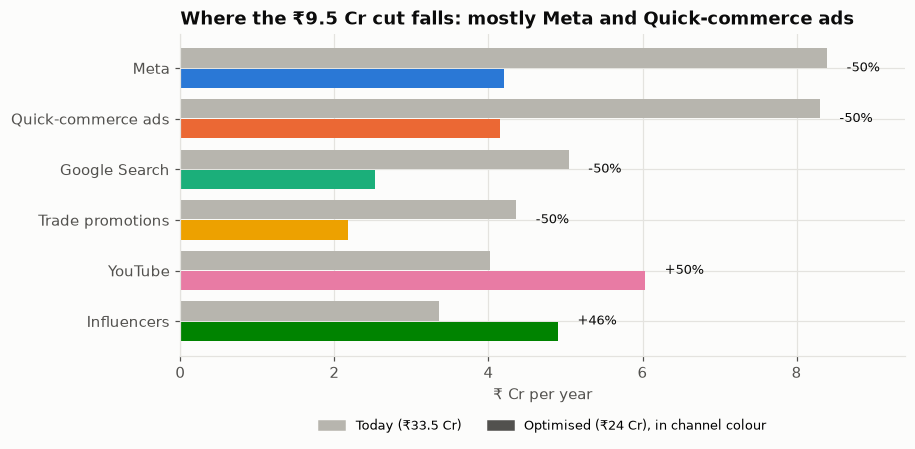

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
names = alloc.index[:-1]
yy = np.arange(len(names))
ax.barh(yy - 0.2, alloc.loc[names, "today ₹ Cr/yr"], height=0.38, color=NEUTRAL)
for j, n in enumerate(names):
    c = [k for k, v in LABEL.items() if v == n][0]
    ax.barh(j + 0.2, alloc.loc[n, "optimised ₹ Cr/yr"], height=0.38, color=COLOR[c])
    ax.text(alloc.loc[n, ["today ₹ Cr/yr", "optimised ₹ Cr/yr"]].max() + 0.25, j, f"{alloc.loc[n, 'change vs today']:+.0%}",
            va="center", fontsize=8.5, color=INK)
from matplotlib.patches import Patch
ax.set_yticks(yy, names); ax.invert_yaxis()
ax.set_xlabel("₹ Cr per year")
ax.legend(handles=[Patch(color=NEUTRAL, label="Today (₹33.5 Cr)"), Patch(color=INK2, label="Optimised (₹24 Cr), in channel colour")],
          frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
ax.set_xlim(0, alloc.loc[names, ["today ₹ Cr/yr", "optimised ₹ Cr/yr"]].values.max() * 1.12)
_cut = alloc.loc[names].sort_values("change vs today").index[:2]
ax.set_title(f"Where the ₹{B_CURRENT - B:.1f} Cr cut falls: mostly {_cut[0]} and {_cut[1]}")
save(fig, "04_allocation"); plt.show()

## 5. Why this split? Equal marginal returns
At the optimum, the last rupee in every channel that is not at a bound earns the same CLV-adjusted
value. Channels pinned at a bound show where the ±50% limit is binding.

In [7]:
eps = 0.01
mv = []
for i, c in enumerate(CHANNELS):
    xp = x_opt.copy(); xp[i] += eps
    mv.append((value(xp) - value(x_opt)).mean() / eps)
lo, hi = current * 0.5, current * 1.5
marg = pd.DataFrame({"marginal value per ₹1": mv,
                     "at bound": ["lower (−50%)" if np.isclose(x, l, rtol=1e-3) else "upper (+50%)" if np.isclose(x, h, rtol=1e-3) else "—"
                                  for x, l, h in zip(x_opt, lo, hi)]}, index=[LABEL[c] for c in CHANNELS])
marg.round(3)

,marginal value per ₹1,at bound
Meta,0.038,lower (−50%)
Quick-commerce ads,0.239,lower (−50%)
Google Search,0.305,lower (−50%)
Trade promotions,0.721,lower (−50%)
YouTube,3.661,upper (+50%)
Influencers,1.694,—


## 6. Scenarios: is the recommendation robust?

In [8]:
scen = {
    "Budget ₹21.6 Cr (−10%)": dict(budget_cr=21.6),
    "Budget ₹24 Cr (base)": dict(budget_cr=24.0),
    "Budget ₹26.4 Cr (+10%)": dict(budget_cr=26.4),
    "QC commission +5 pts": dict(budget_cr=24.0, margin={c: (0.25 if c == "qc_ads" else 0.37 - 0.45 * 0.05) for c in CHANNELS}),
    "CAC +20%": dict(budget_cr=24.0, fv={c: v / 1.2 for c, v in fv_per_rev.items()}),
}
rows = {}
for name, kw in scen.items():
    xs = optimise(**kw)
    m, f = kw.get("margin", BASE_MARGIN), kw.get("fv", fv_per_rev)
    cm = cm_after_marketing(xs, m, f)
    rows[name] = {**{LABEL[c]: xs[i] * 52 / 100 for i, c in enumerate(CHANNELS)},
                  "net contribution ₹ Cr (median)": np.median(cm)}
scen_tbl = pd.DataFrame(rows).T
shares = scen_tbl[[LABEL[c] for c in CHANNELS]].div(scen_tbl[[LABEL[c] for c in CHANNELS]].sum(1), axis=0)
direction = np.sign(scen_tbl[[LABEL[c] for c in CHANNELS]].values / (current * 52 / 100) - 1)
robust = (direction == direction[1]).all(0)
print("Channels whose direction (up/down vs today) holds in every scenario:",
      [LABEL[c] for c, r in zip(CHANNELS, robust) if r])
scen_tbl.round(2)

Channels whose direction (up/down vs today) holds in every scenario: ['Meta', 'Quick-commerce ads', 'Trade promotions', 'YouTube']


,Meta,Quick-commerce ads,Google Search,Trade promotions,YouTube,Influencers,net contribution ₹ Cr (median)
Budget ₹21.6 Cr (−10%),4.2,4.15,2.52,2.18,6.04,2.51,-6.02
Budget ₹24 Cr (base),4.2,4.15,2.52,2.18,6.04,4.91,-3.65
Budget ₹26.4 Cr (+10%),4.2,4.15,7.57,2.18,6.04,2.26,-3.34
QC commission +5 pts,4.2,4.15,2.52,2.18,6.04,4.91,-4.84
CAC +20%,4.2,4.15,2.52,2.18,6.04,4.91,-4.25


## 7. Freeze the recommendation (before opening the answer key)

In [9]:
rec = dict(budget_cr=B, bounds="±50% of current weekly spend", objective="CLV-adjusted contribution (MMM v2 + notebook 05)",
           current_cr={LABEL[c]: round(current[i] * 52 / 100, 3) for i, c in enumerate(CHANNELS)},
           optimised_cr={LABEL[c]: round(x_opt[i] * 52 / 100, 3) for i, c in enumerate(CHANNELS)},
           pro_rata_cr={LABEL[c]: round(x_pro[i] * 52 / 100, 3) for i, c in enumerate(CHANNELS)},
           expected_gain_vs_pro_rata_cr=dict(median=round(float(np.median(gain_vs_pro)), 3),
                                             p5=round(float(np.quantile(gain_vs_pro, .05)), 3),
                                             p95=round(float(np.quantile(gain_vs_pro, .95)), 3)),
           robust_channels=[LABEL[c] for c, r in zip(CHANNELS, robust) if r])
p_rec = ROOT / "model" / "optimiser_recommendation.json"
p_rec.write_text(json.dumps(rec, indent=1))
scen_tbl.to_csv(ROOT / "model" / "optimiser_scenarios.csv")
h = hashlib.sha256(p_rec.read_bytes()).hexdigest()
(ROOT / "model" / "optimiser_FROZEN.txt").write_text(f"SHA-256 of optimiser_recommendation.json: {h}\n")
print("Frozen recommendation fingerprint:", h)

Frozen recommendation fingerprint: ddd7e0ab80d313ec182dfdfd1fd19dad8e2275b56aa577d7a86b689e118c5d16


## 8. So what (for the CFO)

In [10]:
up = alloc.loc[names][alloc.loc[names, "change vs today"] > 0.01].index.tolist()
down = alloc.loc[names].sort_values("change vs today").index.tolist()
print("SO WHAT")
print(f"1. Recommendation: cut to ₹{B:.0f} Cr by taking the most from "
      + ", ".join(f"{n} ({alloc.loc[n, 'change vs today']:+.0%})" for n in down[:2])
      + ("; grow " + ", ".join(f"{n} ({alloc.loc[n, 'change vs today']:+.0%})" for n in up) if up else "") + ".")
print(f"2. Versus cutting every channel equally: +₹{np.median(gain_vs_pro):.1f} Cr a year of contribution "
      f"(90%: {np.quantile(gain_vs_pro, .05):.1f} to {np.quantile(gain_vs_pro, .95):.1f}).")
print(f"3. Versus today: spending ₹{B_CURRENT - B:.1f} Cr less changes media-driven revenue by {np.median(d_rev):+.1f} Cr "
      f"(90%: {np.quantile(d_rev, .05):+.1f} to {np.quantile(d_rev, .95):+.1f}) and improves contribution after marketing by "
      f"₹{np.median(gain_vs_today):.1f} Cr a year (90%: {np.quantile(gain_vs_today, .05):.1f} to {np.quantile(gain_vs_today, .95):.1f}).")
print(f"4. Robust across ±10% budgets, a higher QC commission and 20% higher CAC for: {', '.join(rec['robust_channels'])}.")
print("5. Add the 1-page checkout (notebook 06): about ₹1.0 Cr a year of extra contribution with no ad spend.")

SO WHAT
1. Recommendation: cut to ₹24 Cr by taking the most from Meta (-50%), Quick-commerce ads (-50%); grow YouTube (+50%), Influencers (+46%).
2. Versus cutting every channel equally: +₹10.1 Cr a year of contribution (90%: 6.9 to 12.9).
3. Versus today: spending ₹9.5 Cr less changes media-driven revenue by +7.3 Cr (90%: -1.5 to +13.6) and improves contribution after marketing by ₹13.6 Cr a year (90%: 10.1 to 16.4).
4. Robust across ±10% budgets, a higher QC commission and 20% higher CAC for: Meta, Quick-commerce ads, Trade promotions, YouTube.
5. Add the 1-page checkout (notebook 06): about ₹1.0 Cr a year of extra contribution with no ad spend.
